# 03 · Cleaning and Feature Engineering

**Goal:** run the team's cleaning (`data_loader.py`) and feature (`features.py`) code, check the result, and set up the rolling chronological backtest (`backtest.py`).

In [1]:
import os
import sys

# Find the project folder (the one that contains config.py) and work from there
ROOT = os.getcwd()
while not os.path.exists(os.path.join(ROOT, "config.py")):
    ROOT = os.path.dirname(ROOT)
os.chdir(ROOT)
sys.path.append(ROOT)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import config

FIG = "reports/figures"
OUT = "data/GeneratedOutput/02.FeatureEngineering"
os.makedirs(FIG, exist_ok=True)
os.makedirs(OUT, exist_ok=True)
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

## 1. Clean the data

In [2]:
from data_loader import load_raw_data, clean_data

raw = load_raw_data(config.RAW_FILE)
clean = clean_data(raw)
clean.to_csv(config.CLEAN_FILE)

hour_steps = clean.index.to_series().diff().dropna()
print("Clean rows:", len(clean))
print("Every row is exactly 1 hour apart:", bool((hour_steps == pd.Timedelta(hours=1)).all()))
print("Empty values left:", int(clean.isna().sum().sum()))
print("Hours flagged as missing PM2.5:", int(clean["pm25_missing"].sum()))
clean.head()

Clean rows: 43800
Every row is exactly 1 hour apart: True
Empty values left: 0
Hours flagged as missing PM2.5: 2043


,pm25,DEWP,TEMP,PRES,Iws,Is,Ir,pm25_missing,wind_NE,wind_NW,wind_SE,wind_cv
datetime,,,,,,,,,,,,
2010-01-02 00:00:00,129.0,-16,-4.0,1020.0,1.79,0,0,0,0,0,1,0
2010-01-02 01:00:00,148.0,-15,-4.0,1020.0,2.68,0,0,0,0,0,1,0
2010-01-02 02:00:00,159.0,-11,-5.0,1021.0,3.57,0,0,0,0,0,1,0
2010-01-02 03:00:00,181.0,-7,-5.0,1022.0,5.36,1,0,0,0,0,1,0
2010-01-02 04:00:00,138.0,-7,-5.0,1022.0,6.25,2,0,0,0,0,1,0


## 2. Build the features and the 6-hour-ahead target

In [3]:
from features import build_features, get_feature_columns

features = build_features(clean)
features.to_csv(config.FEATURES_FILE)
feature_cols = get_feature_columns(features)
print("Feature table:", features.shape, "|", len(feature_cols), "features")

Feature table: (43770, 33) | 31 features


In [4]:
def feature_group(name):
    if name == "pm25":
        return "Current PM2.5"
    if name.startswith("pm25_lag") or name == "pm25_same_hour_yesterday":
        return "Lag"
    if name.startswith("pm25_roll"):
        return "Rolling mean"
    if name.startswith("wind_"):
        return "Wind direction"
    if name in ["hour", "day_of_week", "month", "is_weekend", "hour_sin", "hour_cos", "month_sin", "month_cos"]:
        return "Calendar"
    if name == "pm25_missing":
        return "Missing flag"
    return "Weather"

feature_table = pd.DataFrame({"feature": feature_cols})
feature_table["group"] = feature_table["feature"].map(feature_group)
feature_table.to_csv(f"{OUT}/01_feature_list.csv", index=False)
feature_table.groupby("group")["feature"].apply(", ".join).to_frame()

,feature
group,
Calendar,"hour, day_of_week, month, is_weekend, hour_sin..."
Current PM2.5,pm25
Lag,"pm25_lag_1, pm25_lag_2, pm25_lag_3, pm25_lag_6..."
Missing flag,pm25_missing
Rolling mean,"pm25_roll_mean_6, pm25_roll_mean_24"
Weather,"DEWP, TEMP, PRES, Iws, Is, Ir, temp_dewp_gap, ..."
Wind direction,"wind_NE, wind_NW, wind_SE, wind_cv"


## 3. No leakage check

In [5]:
# The target must be PM2.5 exactly 6 hours later, and lag_6 must be PM2.5 exactly 6 hours earlier
check = clean["pm25"]
target_ok = (features["target"] == check.shift(-config.HORIZON).loc[features.index]).all()
lag_ok = (features["pm25_lag_6"] == check.shift(6).loc[features.index]).all()
print("Target is 6 hours ahead:", bool(target_ok))
print("Lag 6 is 6 hours behind:", bool(lag_ok))
print("Rows where the future value was really measured:", int(features["target_observed"].sum()), "of", len(features))

Target is 6 hours ahead: True
Lag 6 is 6 hours behind: True
Rows where the future value was really measured: 41727 of 43770


## 4. Rolling chronological backtest folds

In [6]:
from backtest import make_folds

folds = make_folds(features)
rows = []
for fold, train, test in folds:
    rows.append({
        "fold": fold,
        "train_start": train.index.min(), "train_end": train.index.max(), "train_rows": int(train["target_observed"].sum()),
        "test_start": test.index.min(), "test_end": test.index.max(), "test_rows": int(test["target_observed"].sum()),
    })
fold_table = pd.DataFrame(rows)
fold_table.to_csv(f"{OUT}/02_backtest_folds.csv", index=False)
fold_table

,fold,train_start,train_end,train_rows,test_start,test_end,test_rows
0,1,2010-01-03,2012-12-31 23:00:00,24388,2013-01-01,2013-06-30 23:00:00,4309
1,2,2010-01-03,2013-06-30 23:00:00,28697,2013-07-01,2013-12-31 23:00:00,4369
2,3,2010-01-03,2013-12-31 23:00:00,33066,2014-01-01,2014-06-30 23:00:00,4311
3,4,2010-01-03,2014-06-30 23:00:00,37377,2014-07-01,2014-12-31 17:00:00,4344


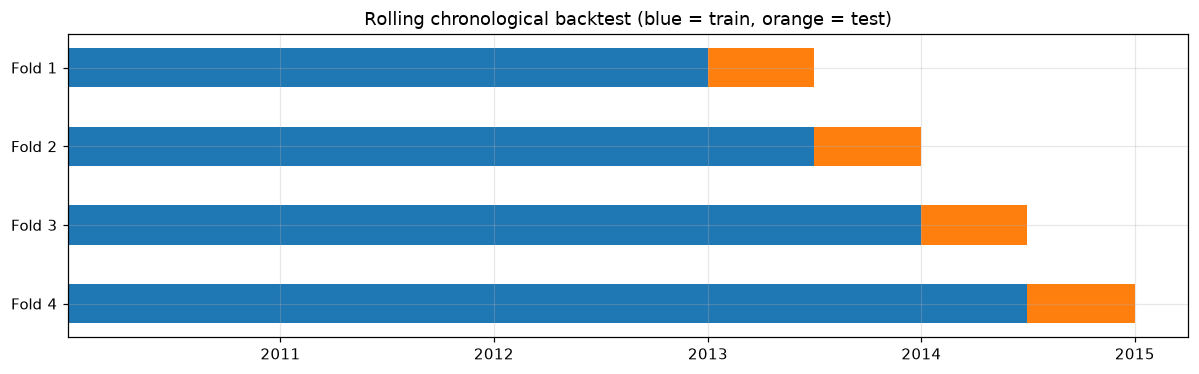

In [7]:
fig, ax = plt.subplots(figsize=(11, 3.5))
for _, row in fold_table.iterrows():
    y = row["fold"]
    ax.barh(y, row["train_end"] - row["train_start"], left=row["train_start"], color="tab:blue", height=0.5)
    ax.barh(y, row["test_end"] - row["test_start"], left=row["test_start"], color="tab:orange", height=0.5)
ax.set_yticks(fold_table["fold"], [f"Fold {f}" for f in fold_table["fold"]])
ax.invert_yaxis()
ax.set_title("Rolling chronological backtest (blue = train, orange = test)")
plt.tight_layout()
plt.savefig(f"{FIG}/08_backtest_folds.png")
plt.show()

## Summary

- 43,800 clean hourly rows, 2,043 flagged as missing PM2.5, and no empty values left.
- **31 features** in 7 groups. The target is PM2.5 **6 hours ahead**, and it is checked to have no leakage.
- **4 folds**: each trains on all earlier data and tests on the next 6 months, so the training window grows from 3 to 4.5 years.